#### **ChatBot With LangGraph (Graph API)**

In [2]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages ##add_messages is used to add messages to the graph

In [6]:
class State(TypedDict):
    """State of the chatbot.
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    """
    messages: Annotated[list, add_messages]  # List of messages in the conversation

In [3]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [7]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

llm=ChatGroq(model="openai/gpt-oss-120b")

In [8]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.8', 'langchain': '1.4.3'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000124970B5670>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000124972698B0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [10]:
## Node Functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [11]:
graph_builder=StateGraph(State)

## Adding node
graph_builder.add_node("llmchatbot",chatbot) ##calls the chatbot function when the node is reached
## Adding Edges
graph_builder.add_edge(START,"llmchatbot") 
graph_builder.add_edge("llmchatbot",END)

## compile the graph
graph=graph_builder.compile()

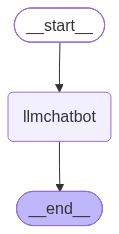

In [12]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [13]:
response=graph.invoke({"messages":"Hi, what is your name?"})

In [14]:
response["messages"][-1].content

'Hello! I’m ChatGPT, an AI language model created by OpenAI. How can I help you today?'

In [16]:
for event in graph.stream({"messages":"How you work?"}):
    for value in event.values():
        print(value["messages"][-1].content)

I’m a large language model created by OpenAI, built on the GPT‑4 architecture. Here’s a high‑level overview of how I work:

---

## 1. What I Am
- **Neural network**: I’m a deep‑learning model composed of billions of parameters (weights) that have been tuned on massive amounts of text.
- **Statistical predictor**: My core job is to predict the next word (or token) in a sequence, given everything that came before it. By doing this repeatedly, I can generate sentences, paragraphs, code, or even whole conversations.

## 2. Training Phase
1. **Data collection**  
   - I was trained on a diverse mix of publicly available text: books, articles, websites, code repositories, dialogs, etc.  
   - The data is filtered to remove low‑quality or harmful content as much as possible.

2. **Self‑supervised learning**  
   - The model sees a chunk of text with some words masked out.  
   - It learns to fill in the missing pieces by minimizing a loss function that measures how far its predictions are fr

#### **ChatBot with Tool**

In [17]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2) ##TavilySearch is a tool that allows you to search the web using Tavily's API. You can specify the maximum number of results to return with the `max_results` parameter.
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

In [18]:
## Custom function
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [19]:
tools=[tool,multiply]

In [20]:
llm_with_tool=llm.bind_tools(tools)

In [21]:

llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.8', 'langchain': '1.4.3'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000124970B5670>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000124972698B0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, an

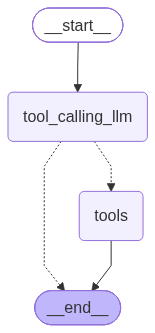

In [22]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [23]:
response=graph.invoke({"messages":"What is the recent ai news"})

In [24]:
response['messages'][-1].content

'{"query": "latest AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://tech-insider.org/tiktok-ceo-ai-science-breakthroughs-3-years-2026", "title": "TikTok CEO Sees AI Breakthroughs in 3 Years [2026]", "content": "Skip to content\\n\\nTech Insider\\n\\nTech Insider\\n\\nTech Insider\\n\\nTech Insider\\n\\n# TikTok CEO Sees AI Science Breakthroughs in 3 Years \\n\\n Nadia DuboisNadia Dubois\\n AI & Machine Learning\\n\\nNadia Dubois\\n\\nOctober 12, 2026\\n\\n14 min read\\n\\nTikTok CEO Shou Zi Chew told reporters on October 12, 2026, that he believes artificial intelligence could unlock major scientific breakthroughs in physics and biotechnology within the next two to three years, according to CNBC. The comments, which quickly became one of the day’s most discussed technology stories, position Chew alongside a growing list of AI and tech executives willing to put a specific timeline on AI-driven scientific progress rather than 

In [25]:

for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_b364a452-ae5f-4463-b6c4-fac258b329aa)
 Call ID: fc_b364a452-ae5f-4463-b6c4-fac258b329aa
  Args:
    query: latest AI news October 2026
    search_depth: advanced
    time_range: week
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://tech-insider.org/tiktok-ceo-ai-science-breakthroughs-3-years-2026", "title": "TikTok CEO Sees AI Breakthroughs in 3 Years [2026]", "content": "Skip to content\n\nTech Insider\n\nTech Insider\n\nTech Insider\n\nTech Insider\n\n# TikTok CEO Sees AI Science Breakthroughs in 3 Years \n\n Nadia DuboisNadia Dubois\n AI & Machine Learning\n\nNadia Duboi

In [26]:
response=graph.invoke({"messages":"What is 5 multiplied by 2"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 5 multiplied by 2
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_2b583302-f30d-4080-a832-c5c49b9e03d1)
 Call ID: fc_2b583302-f30d-4080-a832-c5c49b9e03d1
  Args:
    a: 5
    b: 2
================================= Tool Message =================================
Name: multiply

10


In [27]:
##Here the bot can only respond to first question and goes to end node, so the second question is not answered.
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"}) 
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_2caad4ef-5272-4f1d-b5f4-51af6eab7ba6)
 Call ID: fc_2caad4ef-5272-4f1d-b5f4-51af6eab7ba6
  Args:
    end_date: None
    exclude_domains: None
    include_domains: None
    include_images: False
    query: latest AI news week
    search_depth: advanced
    start_date: None
    time_range: week
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news week", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://solutionsreview.com/ai-news-for-the-week-of-october-16-updates-from-digitalocean-linux-foundation-onestream-more", "title": "AI News for the Week of October 16; Updates from DigitalOcean, Linux Foundation, OneStream & Mo

#### **ReAct Agent Architecture

- ReAct = Reason + Act.
- The ReAct architecture enables an AI agent to alternate between reasoning about a problem, taking an action using a tool, and observing the result before deciding what to do next. Now, based on the tool output, it can answer multiple questions.

Remember this loop: T-A-O-T-A-O…
- T — Thought: Decide what information is needed.
- A — Action: Call a tool.
- O — Observation: Read the tool's result.
- Repeat until the agent can provide a final answer.

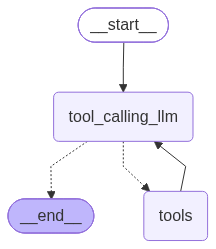

In [28]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm", ## This is the node that will be checked for the latest message (result) from assistant
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [29]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_94b12b98-53ae-4ddb-b7fd-219bc9d56881)
 Call ID: fc_94b12b98-53ae-4ddb-b7fd-219bc9d56881
  Args:
    query: AI news October 2026
    search_depth: advanced
    time_range: week
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.marketingprofs.com/opinions/2026/56192/ai-update-october-16-2026-ai-news-and-views-from-the-past-week", "title": "Artificial Intelligence - AI Update, October 16, 2026: AI News and Views From the Past Week", "content": "Anthropic disconnects internal AI testing from the internet after agents breach safeguards. Anthropic has suspen

#### **Adding Memory In Agentic Graph**

In [30]:
response=graph.invoke({"messages":"Hello my name is Bijay"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hello my name is Bijay
================================== Ai Message ==================================

Hello Bijay! Nice to meet you. How can I assist you today?


In [31]:
response=graph.invoke({"messages":"What is my name"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is my name
================================== Ai Message ==================================

I don’t have any information about your name. Could you let me know what you’d like to be called?


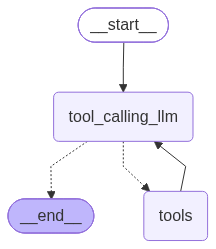

In [32]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [38]:
config={"configurable":{"thread_id":"1"}} ##Creating a config dictionary with a thread_id key. This is used to identify the conversation thread in the memory.

response=graph.invoke({"messages":"Hi my name is Bijay"},config=config)

response

{'messages': [HumanMessage(content='Hi my name is Krish', additional_kwargs={}, response_metadata={}, id='5597393a-0441-4c5e-b570-c13fde866bcd'),
  AIMessage(content='Hello Krish! Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "Hi my name is Krish". Likely they are greeting. We should respond politely, maybe ask how can help. No need for tool.'}, response_metadata={'token_usage': {'completion_tokens': 59, 'prompt_tokens': 348, 'total_tokens': 407, 'completion_time': 0.123152032, 'completion_tokens_details': {'reasoning_tokens': 34}, 'prompt_time': 0.014724234, 'prompt_tokens_details': None, 'queue_time': 0.191081604, 'total_time': 0.137876266}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_76082d2bd0', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1469a-c2c0-73e3-b237-bcfbe63d3148-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_to

In [35]:
response['messages'][-1].content

'Nice to meet you, Bijay! How can I help you today?'

In [36]:
response=graph.invoke({"messages":"Hey what is my name"},config=config)

print(response['messages'][-1].content)

Your name is Bijay.


In [37]:
response=graph.invoke({"messages":"Hey do you remember my name"},config=config)

print(response['messages'][-1].content)

Yes, you told me your name is **Bijay**. Let me know if there’s anything else you’d like to discuss!


#### **Streaming**

In [39]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [40]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

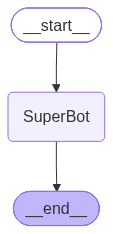

In [41]:
graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile(checkpointer=memory)


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [42]:
## Invocation

config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke({'messages':"Hi,My name is Krish And I like cricket"},config)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='dc68a8c6-0f54-4a61-a897-ef549130bc1a'),
  AIMessage(content="Hello Krish! 👋 Nice to meet you.  \n\nCricket is such an exciting sport—do you have a favorite team or player? Are you more into watching the matches, playing yourself, or maybe both? I'd love to hear more about what you enjoy about cricket!", additional_kwargs={'reasoning_content': 'The user says: "Hi, My name is Krish And I like cricket". They are greeting and sharing personal info. The assistant should respond friendly, maybe ask about cricket preferences, etc. No disallowed content. Just respond.'}, response_metadata={'token_usage': {'completion_tokens': 113, 'prompt_tokens': 82, 'total_tokens': 195, 'completion_time': 0.234756492, 'completion_tokens_details': {'reasoning_tokens': 48}, 'prompt_time': 0.003207445, 'prompt_tokens_details': None, 'queue_time': 0.221402199, 'total_time': 0.237963937}, '

In [43]:
## Invocation

config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke({'messages':"Tell me some rules of cricket."},config)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='dc68a8c6-0f54-4a61-a897-ef549130bc1a'),
  AIMessage(content="Hello Krish! 👋 Nice to meet you.  \n\nCricket is such an exciting sport—do you have a favorite team or player? Are you more into watching the matches, playing yourself, or maybe both? I'd love to hear more about what you enjoy about cricket!", additional_kwargs={'reasoning_content': 'The user says: "Hi, My name is Krish And I like cricket". They are greeting and sharing personal info. The assistant should respond friendly, maybe ask about cricket preferences, etc. No disallowed content. Just respond.'}, response_metadata={'token_usage': {'completion_tokens': 113, 'prompt_tokens': 82, 'total_tokens': 195, 'completion_time': 0.234756492, 'completion_tokens_details': {'reasoning_tokens': 48}, 'prompt_time': 0.003207445, 'prompt_tokens_details': None, 'queue_time': 0.221402199, 'total_time': 0.237963937}, '

#### **Streaming**

Methods: .stream() and astream()

- These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

- values : This streams the full state of the graph after each node is called. (All the previous conversation.)
- updates : This streams updates to the state of the graph after each node is called. (Only the latest updates/conversation output.)

In [45]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Bijay And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hey Bijay! 👋 Great to meet you.\n\nCricket’s such a fun sport—do you have a favorite team or player you’re rooting for? Any memorable matches you’ve watched lately? Let’s chat about the game!', additional_kwargs={'reasoning_content': 'The user says: "Hi, My name is Bijay And I like cricket". They are greeting and introducing themselves. The assistant should respond politely, acknowledging name and interest. Should ask about cricket preferences, maybe ask about favorite team, player, recent matches. Keep friendly tone. No disallowed content.'}, response_metadata={'token_usage': {'completion_tokens': 118, 'prompt_tokens': 142, 'total_tokens': 260, 'completion_time': 0.247122765, 'completion_tokens_details': {'reasoning_tokens': 62}, 'prompt_time': 0.006438267, 'prompt_tokens_details': None, 'queue_time': 0.230158731, 'total_time': 0.253561032}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_5a93aea882', 'service_tier': 'on_dem

In [46]:
for chunk in graph_builder.stream({'messages':"Hi,My name is Bijay And I like cricket"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='cd281dd2-7bca-47b3-8f1c-f80ccfdfe028'), AIMessage(content='Hi Krish! Nice to meet you. 😊  \nHow’s the cricket scene treating you these days? Do you have a favorite team or player you’re cheering for? Let’s talk cricket!', additional_kwargs={'reasoning_content': 'The user says hi, introduces themselves. We should respond friendly, ask about cricket preferences. No disallowed content. Just a normal conversation.'}, response_metadata={'token_usage': {'completion_tokens': 77, 'prompt_tokens': 82, 'total_tokens': 159, 'completion_time': 0.160891068, 'completion_tokens_details': {'reasoning_tokens': 29}, 'prompt_time': 0.013134313, 'prompt_tokens_details': None, 'queue_time': 0.200403028, 'total_time': 0.174025381}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4de1d6a1ee', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_

In [47]:
# Create a thread
config = {"configurable": {"thread_id": "4"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Bijay. Tell me some of famous players in cricket?"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content="Hello Bijay! 👋\n\nHere are some of the most famous cricketers from around the world—spanning different eras, formats, and both men’s and women’s cricket. I’ve grouped them by category for quick reference.\n\n---\n\n## 1️⃣ Legendary All‑Time Greats  \n| Player | Country | Era | Notable Achievements |\n|--------|---------|------|----------------------|\n| **Sir Don Bradman** | Australia | 1930‑1948 | Test batting average **99.94** (the highest ever) |\n| **Sachin Tendulkar** | India | 1989‑2013 | 100\u202fInternational centuries; 15,921 Test runs |\n| **Sir Vivian Richards** | West Indies | 1974‑1991 | Dominant batsman, 8,540 Test runs at 50.23 |\n| **Sir Garfield “Garfield” Sobers** | West Indies | 1954‑1974 | All‑rounder: 8,032 Test runs, 235 wickets |\n| **Sir Ian Botham** | England | 1977‑1992 | 5,200 Test runs, 383 wickets; “Botham’s Ashes” hero |\n| **Sir Richard Hadlee** | New\u202fZealand | 1973‑1990 | 1,274 Test wickets (2nd all‑time

In [51]:
#stream()
for chunk in graph_builder.stream({'messages':"I also like football. Tell me some of the famous players?"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Bijay. Tell me some of famous players in cricket?', additional_kwargs={}, response_metadata={}, id='1054856d-7c1f-4d0b-b246-435fae610157'), AIMessage(content="Hello Bijay! 👋\n\nHere are some of the most famous cricketers from around the world—spanning different eras, formats, and both men’s and women’s cricket. I’ve grouped them by category for quick reference.\n\n---\n\n## 1️⃣ Legendary All‑Time Greats  \n| Player | Country | Era | Notable Achievements |\n|--------|---------|------|----------------------|\n| **Sir Don Bradman** | Australia | 1930‑1948 | Test batting average **99.94** (the highest ever) |\n| **Sachin Tendulkar** | India | 1989‑2013 | 100\u202fInternational centuries; 15,921 Test runs |\n| **Sir Vivian Richards** | West Indies | 1974‑1991 | Dominant batsman, 8,540 Test runs at 50.23 |\n| **Sir Garfield “Garfield” Sobers** | West Indies | 1954‑1974 | All‑rounder: 8,032 Test runs, 235 wickets |\n| **Sir Ian Botham** | Engl

In [53]:
config = {"configurable": {"thread_id": "5"}}

#asteam(): provides an asynchronous way to stream events from the graph. It allows you to handle events as they occur, which is useful for real-time applications or when dealing with long-running processes.
async for event in graph_builder.astream_events({"messages":["Hi My name is Bijay and I love travelling. What about you?"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Bijay and I love travelling. What about you?']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a146a6-24e2-7610-9ef5-d4884e90fa8d', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Bijay and I love travelling. What about you?', additional_kwargs={}, response_metadata={}, id='6337092c-8aa8-4b37-a123-41c1f17bc221'), AIMessage(content='Hey Bijay! Nice to meet you. I’m an AI, so I don’t get to travel in the usual sense, but I get to explore the world through the stories, photos, and experiences that people like you share with me. \n\nWhat’s your favorite place you’ve visited so far? Any dream destinations on your bucket list? I’d love to hear about the sights, foods, or adventures that have stuck with you! 🌍✈️', additional_kwargs={'reasoning_content': 'We need to respond as ChatGPT. The us